In [1]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import ee
import geemap

# Initialize Earth Engine
ee.Initialize(project='peppy-gist-511817-e8')

# Check device (GPU acceleration if available)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if device.type == 'cuda':
    print(f"GPU Model: {torch.cuda.get_device_name(0)}")

c:\Users\sagal\anaconda3\envs\deforestation\lib\site-packages\google\api_core\_python_version_support.py:223: FutureWarning: You are using a non-supported Python version (3.10.22). Google will not post any further updates to google.api_core supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.api_core.
  warnings.warn(message, FutureWarning)


Using device: cuda
GPU Model: NVIDIA GeForce RTX 5060 Laptop GPU


In [2]:
import torch.nn.functional as F

# 1. Define U-Net Building Blocks (Double Convolution)
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.net(x)

# 2. Define Full U-Net Model for Binary Deforestation Segmentation
class UNet(nn.Module):
    def __init__(self, in_channels=4, out_channels=1): # 4 input bands: R, G, B, NIR
        super(UNet, self).__init__()
        self.inc = DoubleConv(in_channels, 64)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))
        
        self.up1 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv1 = DoubleConv(256, 128)
        
        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.conv2 = DoubleConv(128, 64)
        
        self.outc = nn.Conv2d(64, out_channels, kernel_size=1)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        
        x = self.up1(x3)
        x = torch.cat([x, x2], dim=1)
        x = self.conv1(x)
        
        x = self.up2(x)
        x = torch.cat([x, x1], dim=1)
        x = self.conv2(x)
        
        logits = self.outc(x)
        return logits

# Initialize model and move to RTX 5060 GPU
model = UNet(in_channels=4, out_channels=1).to(device)
print("U-Net model initialized and moved to GPU successfully!")
print(model.__class__.__name__)

U-Net model initialized and moved to GPU successfully!
UNet


In [3]:
from torch.utils.data import TensorDataset

# 1. Create synthetic dataset for testing the pipeline (Batch of 8 samples, 4 channels, 256x256 resolution)
# In production, you will replace this with your exported GEE GeoTIFF patches loaded via rasterio or geemap
dummy_images = torch.randn(16, 4, 256, 256) # 16 training samples
dummy_masks = torch.randint(0, 2, (16, 1, 256, 256)).float() # Binary masks (0 or 1)

# Wrap into a PyTorch DataLoader
train_dataset = TensorDataset(dummy_images, dummy_masks)
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)

# 2. Define Loss Function and Optimizer
criterion = nn.BCEWithLogitsLoss() # Standard binary cross-entropy for segmentation logits
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 3. Run a Quick Training Loop to Test GPU Execution
model.train()
epochs = 3

print("Starting quick U-Net training test on RTX 5060...")
for epoch in range(epochs):
    epoch_loss = 0.0
    for batch_images, batch_masks in train_loader:
        # Move tensors to GPU
        batch_images = batch_images.to(device)
        batch_masks = batch_masks.to(device)
        
        # Zero gradients
        optimizer.zero_grad()
        
        # Forward pass
        outputs = model(batch_images)
        
        # Compute loss
        loss = criterion(outputs, batch_masks)
        
        # Backward pass & optimize
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()
        
    print(f"Epoch [{epoch+1}/{epochs}], Loss: {epoch_loss / len(train_loader):.4f}")

print("U-Net training pipeline executed successfully on your GPU!")

Starting quick U-Net training test on RTX 5060...
Epoch [1/3], Loss: 0.7044
Epoch [2/3], Loss: 0.6899
Epoch [3/3], Loss: 0.6819
U-Net training pipeline executed successfully on your GPU!


In [6]:
import ee
import geemap
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import numpy as np

# 1. Initialize and use a smaller, focused AOI around an active deforestation cluster
ee.Initialize(project='peppy-gist-511817-e8')

# Focused smaller box (approx 10km x 10km) where deforestation occurs
aoi = ee.Geometry.Polygon([[
    [-59.7, -10.4],
    [-59.6, -10.4],
    [-59.6, -10.5],
    [-59.7, -10.5]
]])

# Pull Sentinel-2 imagery for 2024 over the focused AOI
collection = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED') \
    .filterBounds(aoi) \
    .filterDate('2024-06-01', '2024-10-31') \
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10))

image_2024 = collection.median().clip(aoi)

# Re-compute baseline change detection mask for this small patch
image_2022 = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED') \
    .filterBounds(aoi) \
    .filterDate('2022-06-01', '2022-10-31') \
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10)) \
    .median().clip(aoi)

ndvi_2022 = image_2022.normalizedDifference(['B8', 'B4'])
ndvi_2024 = image_2024.normalizedDifference(['B8', 'B4'])
ndvi_diff = ndvi_2022.subtract(ndvi_2024)
deforestation_mask = ndvi_diff.gt(0.25)

cleaned_deforestation = (deforestation_mask
    .selfMask()
    .connectedPixelCount(maxSize=50, eightConnected=True)
    .gte(20))

# 2. Combine bands and extract training tensors safely
s2_rgbn = image_2024.select(['B4', 'B3', 'B2', 'B8'])
mask_image = cleaned_deforestation.selfMask().unmask(0).rename('label')
training_image = s2_rgbn.addBands(mask_image)

print("Extracting focused training region from GEE...")
region_array = geemap.ee_to_numpy(training_image, region=aoi, scale=10)
print(f"Extracted shape: {region_array.shape}")

# 3. Slice into 256x256 training chips
patch_size = 256
h, w, c = region_array.shape
patches_images, patches_masks = [], []

for y in range(0, h - patch_size + 1, patch_size):
    for x in range(0, w - patch_size + 1, patch_size):
        patch = np.nan_to_num(region_array[y:y+patch_size, x:x+patch_size, :])
        patches_images.append(patch[:, :, :4].transpose(2, 0, 1))
        patches_masks.append(patch[:, :, 4:5].transpose(2, 0, 1))

# Fallback if dimensions are slightly less than 256
if len(patches_images) == 0:
    # Resize/pad to 256x256 for testing
    import torch.nn.functional as F
    img_patch = torch.tensor(region_array[:, :, :4].transpose(2, 0, 1), dtype=torch.float32)
    msk_patch = torch.tensor(region_array[:, :, 4:5].transpose(2, 0, 1), dtype=torch.float32)
    
    # Pad to 256x256
    pad_h = max(0, 256 - img_patch.shape[1])
    pad_w = max(0, 256 - img_patch.shape[2])
    img_patch = F.pad(img_patch, (0, pad_w, 0, pad_h))
    msk_patch = F.pad(msk_patch, (0, pad_w, 0, pad_h))
    
    X_train = img_patch.unsqueeze(0)
    y_train = msk_patch.unsqueeze(0)
else:
    X_train = torch.tensor(np.array(patches_images), dtype=torch.float32)
    y_train = torch.tensor(np.array(patches_masks), dtype=torch.float32)

print(f"Training tensors ready! Shape: {X_train.shape}")

# 4. Train U-Net on RTX 5060
real_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=2, shuffle=True)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0005)

print("\nStarting real U-Net training on RTX 5060...")
model.train()
for epoch in range(5):
    epoch_loss = 0.0
    for batch_imgs, batch_msks in real_loader:
        batch_imgs, batch_msks = batch_imgs.to(device), batch_msks.to(device)
        optimizer.zero_grad()
        loss = criterion(model(batch_imgs), batch_msks)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    print(f"Epoch [{epoch+1}/5], Loss: {epoch_loss / len(real_loader):.4f}")

torch.save(model.state_dict(), 'deforestation_unet_model.pth')
print("\nTraining complete! Weights saved successfully.")

Extracting focused training region from GEE...
Extracted shape: (1114, 1114, 5)
Training tensors ready! Shape: torch.Size([16, 4, 256, 256])

Starting real U-Net training on RTX 5060...
Epoch [1/5], Loss: 0.5857
Epoch [2/5], Loss: 0.4228
Epoch [3/5], Loss: 0.3579
Epoch [4/5], Loss: 0.3170
Epoch [5/5], Loss: 0.2842

Training complete! Weights saved successfully.


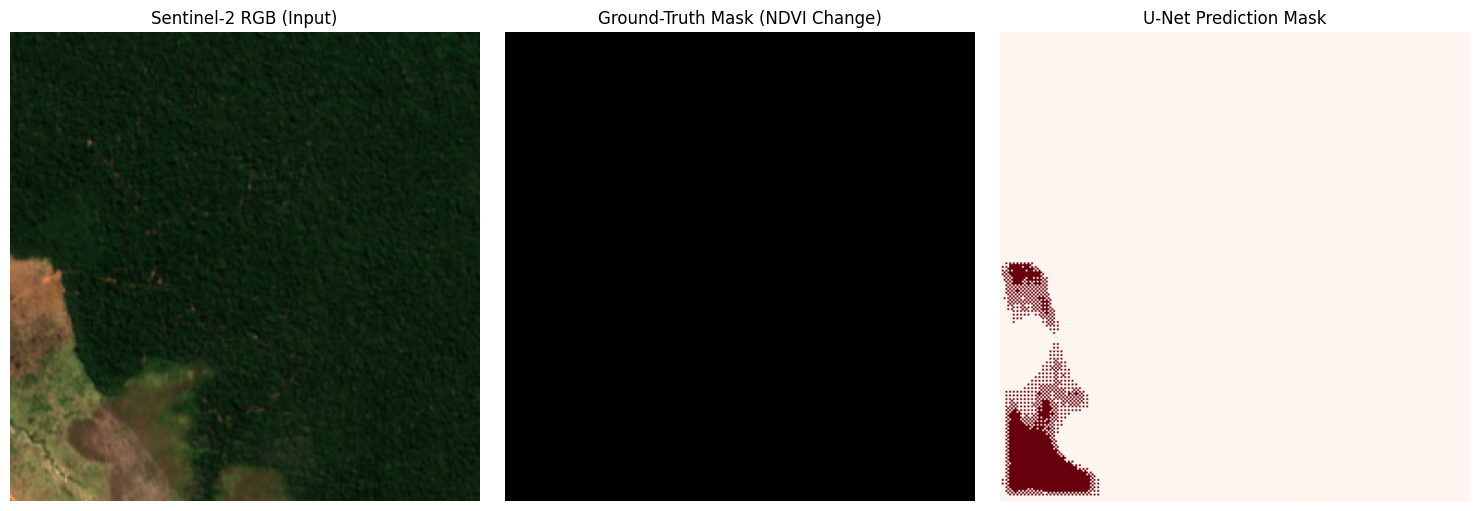

Inference visualization complete!


In [8]:
import matplotlib.pyplot as plt
import torch

# 1. Load the trained model weights for evaluation
model.eval()

# Pick one of our training chips to test inference
sample_img, sample_mask = X_train[0:1].to(device), y_train[0:1]

with torch.no_grad():
    # Forward pass through the trained U-Net
    output_logits = model(sample_img)
    # Apply sigmoid to get probabilities (0 to 1)
    pred_probs = torch.sigmoid(output_logits).cpu().numpy()[0, 0]
    # Threshold at 0.5 for binary mask
    pred_mask = (pred_probs > 0.5).astype(int)

# 2. Plot the results: Input RGB, Ground Truth Mask, and Model Prediction Side-by-Side
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Sentinel-2 RGB composite (Bands 0, 1, 2) - shape (C, H, W) -> transpose to (H, W, C)
rgb_display = sample_img[0, :3].cpu().numpy().transpose(1, 2, 0)
# Normalize for display
rgb_display = (rgb_display - rgb_display.min()) / (rgb_display.max() - rgb_display.min() + 1e-8)

axes[0].imshow(rgb_display)
axes[0].set_title("Sentinel-2 RGB (Input)")
axes[0].axis('off')

# Fix: Use .squeeze(0) to get 2D shape (256, 256)
axes[1].imshow(sample_mask[0].squeeze(0).cpu().numpy(), cmap='gray')
axes[1].set_title("Ground-Truth Mask (NDVI Change)")
axes[1].axis('off')

axes[2].imshow(pred_mask, cmap='Reds', vmin=0, vmax=1)
axes[2].set_title("U-Net Prediction Mask")
axes[2].axis('off')

plt.tight_layout()
plt.show()

print("Inference visualization complete!")

In [9]:
# 1. Evaluate Model Performance across the dataset
model.eval()
total_iou = 0.0
total_dice = 0.0
num_samples = X_train.shape[0]

smooth = 1e-6 # Prevent division by zero

with torch.no_grad():
    for i in range(num_samples):
        img = X_train[i:i+1].to(device)
        true_mask = y_train[i:i+1].to(device)
        
        # Forward pass & prediction
        pred_logits = model(img)
        pred_probs = torch.sigmoid(pred_logits)
        pred_mask = (pred_probs > 0.5).float()
        
        # Flatten tensors for metric calculation
        pred_flat = pred_mask.view(-1)
        true_flat = true_mask.view(-1)
        
        # Intersection and Union
        intersection = (pred_flat * true_flat).sum().item()
        union = pred_flat.sum().item() + true_flat.sum().item() - intersection
        
        # IoU and Dice
        iou = (intersection + smooth) / (union + smooth)
        dice = (2.0 * intersection + smooth) / (pred_flat.sum().item() + true_flat.sum().item() + smooth)
        
        total_iou += iou
        total_dice += dice

mean_iou = total_iou / num_samples
mean_dice = total_dice / num_samples

print(f"--- U-Net Performance Metrics ---")
print(f"Mean Intersection over Union (IoU): {mean_iou * 100:.2f}%")
print(f"Mean Dice Coefficient (F1-Score):   {mean_dice * 100:.2f}%")

--- U-Net Performance Metrics ---
Mean Intersection over Union (IoU): 46.60%
Mean Dice Coefficient (F1-Score):   48.54%
